## Load

In [1]:
import pandas as pd, glob, zipfile
import matplotlib.pyplot as plt

df = pd.concat([pd.read_csv(f) for f in glob.glob("data/daily/*.csv")], ignore_index=True)
print(len(df))
df.head()

355721


,service_date,trip_id,stop_sequence,direction_id,start_time,stop_id,arrival_delay,arrival_time,departure_delay,departure_time,vehicle_label,last_seen,snapshots,start_date,current_stop_sequence,header_TimeStamp
0,20220401.0,101-02.010422.16.0435,1.0,0,04:35:00,2155269,NaN,NaN,613.0,1648748713.0,04:35am Tallawong - Chatswood,1.648754e+09,381.0,NaN,NaN,NaN
1,20220401.0,101-02.010422.16.0435,2.0,0,04:35:00,2155267,586.0,1648748806.0,641.0,1648748861.0,04:35am Tallawong - Chatswood,1.648754e+09,381.0,NaN,NaN,NaN
2,20220401.0,101-02.010422.16.0435,3.0,0,04:35:00,2155265,570.0,1648748970.0,630.0,1648749030.0,04:35am Tallawong - Chatswood,1.648754e+09,381.0,NaN,NaN,NaN
3,20220401.0,101-02.010422.16.0435,4.0,0,04:35:00,2153402,600.0,1648749120.0,657.0,1648749177.0,04:35am Tallawong - Chatswood,1.648754e+09,381.0,NaN,NaN,NaN
4,20220401.0,101-02.010422.16.0435,5.0,0,04:35:00,2153404,575.0,1648749275.0,632.0,1648749332.0,04:35am Tallawong - Chatswood,1.648754e+09,381.0,NaN,NaN,NaN


## Convert time and adds columns

In [2]:
for col in ["arrival_time", "departure_time"]:
    df[col] = pd.to_datetime(df[col], unit="s", utc=True).dt.tz_convert("Australia/Sydney")

df["time"] = df["arrival_time"].fillna(df["departure_time"])
df = df.dropna(subset=["time"])

df["dwell"] = (df["departure_time"] - df["arrival_time"]).dt.total_seconds()
df["hour"] = df["time"].dt.hour
df["weekday"] = df["time"].dt.day_name()
df["date"] = pd.to_datetime(df["service_date"].astype("Int64").astype(str), format="%Y%m%d", errors="coerce")

## Adds station names

In [3]:
with zipfile.ZipFile("data/timetables/timetable_20220405.zip") as z:
    stops = pd.read_csv(z.open("stops.txt"), dtype={"stop_id": str})

df["stop_id"] = df["stop_id"].astype(str)
df = df.merge(stops[["stop_id", "stop_name"]], on="stop_id", how="left")
df["station"] = df["stop_name"].str.replace(r" Station Platform \d+", "", regex=True)
df["station"].unique()       # should list the 13 stations, Tallawong to Chatswood

<StringArray>
[           'Tallawong',           'Rouse Hill',           'Kellyville',
          'Bella Vista',              'Norwest',     'Hills Showground',
          'Castle Hill',          'Cherrybrook',               'Epping',
 'Macquarie University',       'Macquarie Park',           'North Ryde',
            'Chatswood']
Length: 13, dtype: str

## finds weird delays

In [4]:
weird = df[df["arrival_delay"].abs() > 3600]
print(len(weird), "rows more than an hour off")
weird[["date", "trip_id", "station", "arrival_delay"]].head(20)

38 rows more than an hour off


,date,trip_id,station,arrival_delay
64617,2022-04-19,109-25.190422.15.2157,Cherrybrook,6972.0
64618,2022-04-19,109-25.190422.15.2157,Castle Hill,6950.0
64619,2022-04-19,109-25.190422.15.2157,Hills Showground,6988.0
64620,2022-04-19,109-25.190422.15.2157,Norwest,6963.0
64621,2022-04-19,109-25.190422.15.2157,Bella Vista,6996.0
64622,2022-04-19,109-25.190422.15.2157,Kellyville,6965.0
64623,2022-04-19,109-25.190422.15.2157,Rouse Hill,6952.0
65266,2022-04-19,112-25.190422.15.2217,Cherrybrook,3940.0
65267,2022-04-19,112-25.190422.15.2217,Castle Hill,4348.0
65268,2022-04-19,112-25.190422.15.2217,Hills Showground,4388.0


## gets rid of the weird delays

In [5]:
clean = df[df["arrival_delay"].abs() <= 3600]

In [6]:
off = clean[clean["arrival_delay"].abs().between(150, 300)]
print(len(off), "rows")
print(off["hour"].value_counts().sort_index())
print(off["date"].value_counts().head(10))

20177 rows
hour
0       29
1       29
2        6
4        6
5       33
6      159
7     1067
8     1965
9     1958
10     526
11      94
12      22
13      65
14      50
15    1469
16    2981
17    3651
18    4120
19    1733
20      93
21      25
22      17
23      79
Name: count, dtype: int64
date
2022-04-07    1992
2022-05-13    1805
2022-04-01    1740
2022-06-23    1615
2022-05-27    1036
2022-06-14     864
2022-05-05     855
2022-04-06     804
2022-05-03     803
2022-04-08     722
Name: count, dtype: int64


In [7]:
# Do the values pile up near ±240 seconds?
print(off["arrival_delay"].round(-1).value_counts().head(10))

# Is each trip shifted by a fixed amount (low std) or messy (high std)?
off.groupby("trip_id")["arrival_delay"].agg(["count", "mean", "std"]).sort_values("count", ascending=False).head(10)

arrival_delay
 200.0    2102
 220.0    1959
 210.0    1881
-260.0    1689
 230.0    1161
-270.0    1147
-240.0    1077
-250.0    1060
 190.0    1036
 240.0    1027
Name: count, dtype: int64


,count,mean,std
trip_id,,,
101-06.160522.15.0717,24,219.458333,25.253462
127-06.200622.15.1825,24,-252.541667,18.863305
129-06.110422.15.1837,24,-15.458333,245.551904
112-18.200622.15.1733,24,-257.25,19.296880
124-04.200622.15.1645,24,-256.875,18.820231
127-07.020522.15.1907,24,236.25,18.482071
132-05.040422.15.1819,24,205.875,20.883346
130-04.200622.15.1725,24,-252.833333,18.310526
109-16.200622.15.1553,24,-258.833333,18.642324


## shifted trips

In [8]:
trip_stats = clean.groupby(["date", "trip_id"])["arrival_delay"].agg(["mean", "std"])
shifted = trip_stats[trip_stats["mean"].abs().between(150, 300) & (trip_stats["std"] < 60)]
print(len(shifted), "of", len(trip_stats), "trips look shifted by one headway")
print(shifted.reset_index()["date"].value_counts().head(10))

final = clean.set_index(["date", "trip_id"]).drop(shifted.index).reset_index()
print("On time (within 1 min):", round(final["arrival_delay"].abs().le(60).mean() * 100, 1), "%")

1699 of 26564 trips look shifted by one headway
date
2022-04-07    166
2022-05-13    146
2022-04-01    145
2022-06-23    130
2022-05-27     91
2022-05-05     72
2022-06-14     72
2022-04-06     67
2022-05-03     65
2022-04-08     60
Name: count, dtype: int64
On time (within 1 min): 89.6 %


In [9]:
s = shifted.reset_index()
print(s["date"].dt.day_name().value_counts())

print("Early by >1 min:", round((final["arrival_delay"] < -60).mean() * 100, 1), "%")
print("Late by >1 min:", round((final["arrival_delay"] > 60).mean() * 100, 1), "%")
print("Within 5 min:", round(final["arrival_delay"].abs().le(300).mean() * 100, 1), "%")

date
Friday       500
Thursday     375
Tuesday      335
Wednesday    220
Monday       190
Sunday        40
Saturday      39
Name: count, dtype: int64
Early by >1 min: 6.8 %
Late by >1 min: 3.6 %
Within 5 min: 95.0 %


In [10]:
# Which weekdays have the most mis-matched trips?
s = shifted.reset_index()
print(s["date"].dt.day_name().value_counts())

# Early vs late, after cleaning
print("Early by >1 min:", round((final["arrival_delay"] < -60).mean() * 100, 1), "%")
print("Late by >1 min:", round((final["arrival_delay"] > 60).mean() * 100, 1), "%")
print("Within 5 min:", round(final["arrival_delay"].abs().le(300).mean() * 100, 1), "%")

# How many arrivals are in the final data
print("Arrivals:", len(final))

date
Friday       500
Thursday     375
Tuesday      335
Wednesday    220
Monday       190
Sunday        40
Saturday      39
Name: count, dtype: int64
Early by >1 min: 6.8 %
Late by >1 min: 3.6 %
Within 5 min: 95.0 %
Arrivals: 296617


## Charts

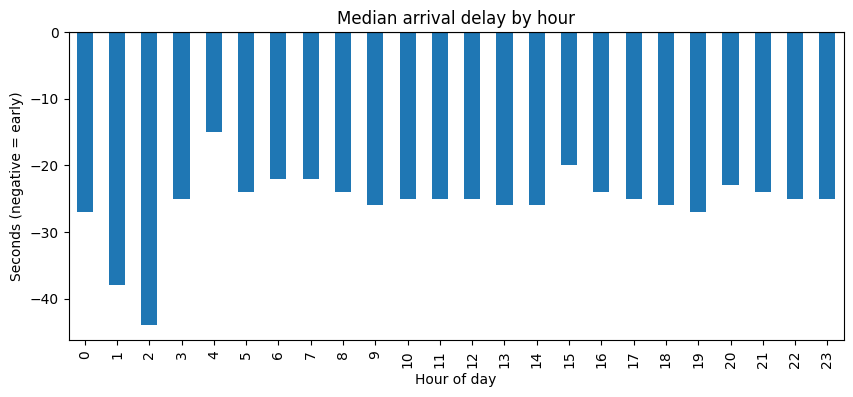

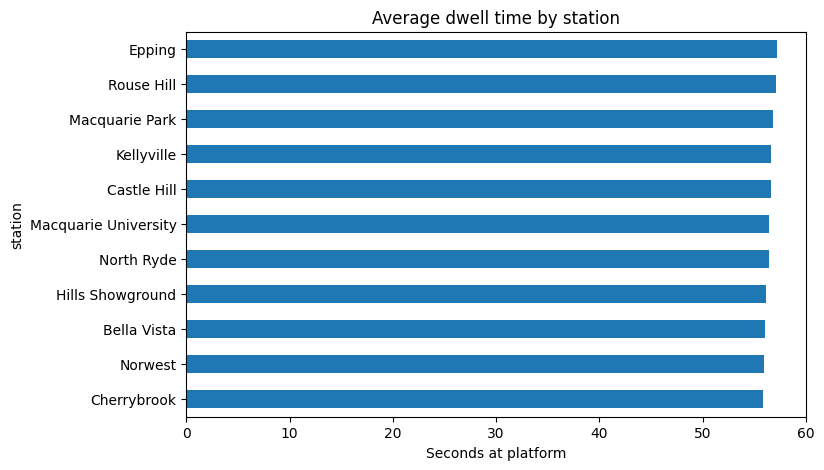

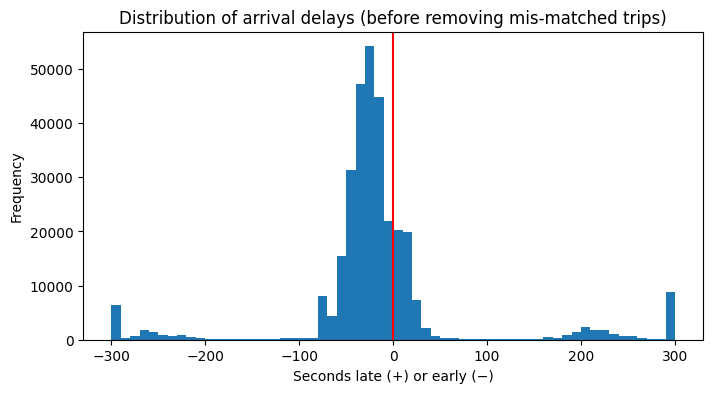

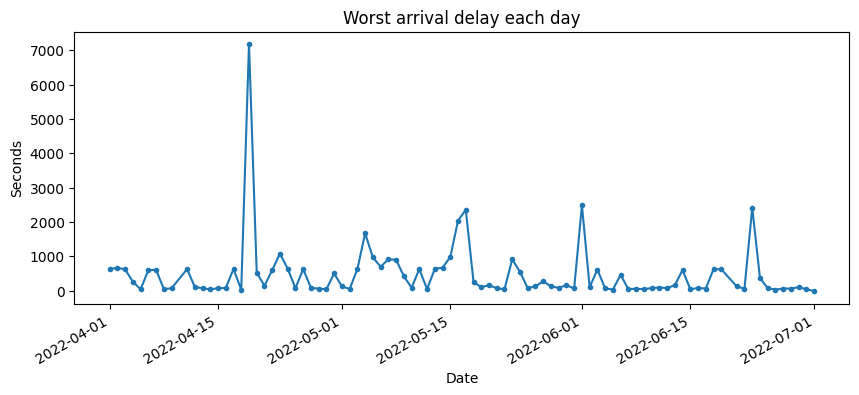

In [11]:
import os
os.makedirs("figures", exist_ok=True)

# 1. Median arrival delay by hour (after removing mis-matched trips)
fig, ax = plt.subplots(figsize=(10, 4))
final.groupby("hour")["arrival_delay"].median().plot(kind="bar", ax=ax)
ax.axhline(0, color="black", linewidth=0.8)
ax.set(title="Median arrival delay by hour", xlabel="Hour of day", ylabel="Seconds (negative = early)")
plt.savefig("figures/median_delay_by_hour.png", dpi=150, bbox_inches="tight")
plt.show()

# 2. Average dwell time by station (end stations have no dwell, so they're dropped)
fig, ax = plt.subplots(figsize=(8, 5))
final.groupby("station")["dwell"].mean().dropna().sort_values().plot(kind="barh", ax=ax)
ax.set(title="Average dwell time by station", xlabel="Seconds at platform")
plt.show()

# 3. Delay distribution BEFORE removing mis-matched trips (shows the ±4 min bumps)
fig, ax = plt.subplots(figsize=(8, 4))
clean["arrival_delay"].clip(-300, 300).plot(kind="hist", bins=60, ax=ax)
ax.axvline(0, color="red")            # red line = exactly on time
ax.set(title="Distribution of arrival delays (before removing mis-matched trips)",
       xlabel="Seconds late (+) or early (−)")
plt.savefig("figures/delay_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

# 4. Worst delay each day (full data, so the spikes still show)
fig, ax = plt.subplots(figsize=(10, 4))
df.groupby("date")["arrival_delay"].max().plot(ax=ax, marker=".")
ax.set(title="Worst arrival delay each day", xlabel="Date", ylabel="Seconds")
plt.show()